<center><font size="4"><b>Technologia Mowy 2026</b></font></center>
<br />
<center><font size="6"><b><u>Lab 4: Modelowanie generatywne sygnału mowy</u></b></font></center>
<br />
<br />

<center><b>Notebook version:</b> 0.19 (5.11.2026)</center>
<center>Copyright Marcin Witkowski, AGH, 2026</center>


# Cele ćwiczenia*

W ramach tego notatnika:

*   Zapoznasz się z interfejsami metod do generowania modelu **mikstur Gaussowskich (GMM)**
*   Korzystając z implementacji wytrenujesz model GMM oraz przeanalizujesz jego działanie
*   Posługując się **naiwnym klasyfikatorem Bayesa** określisz prawdopodobieństwa wystąpienia głosek w plikach audio.



# Wstęp*

Jest wiele rodzajów sposobów modelowania mowy. Jeden ze sposobów rozróżniania modeli wskazuje 2 klasy modeli:
1.  dyskryminatywne;
2.  generatywne.

Modele dyskryminatywne służą na ogół klasyfikacji modelowanych danych. Do przykładów modeli dyskryminatywnych można zaliczyć m. in. sieci neuronowe, drzewa decyzyjne czy maszynę wektorów nośnych (Support Vector Machine). Modele generatywne przyjmują pewne założenia dotyczące charakteru danych i korzystając z przyjętych założeń są w stanie określić prawdopodobieństwo wystąpienia danych lub nawet wygenerować nowe dane.

Osby zainteresowane rozróżnieniem między tymi rodzajami modelu odnoszę do strony [Discriminative Models](https://en.wikipedia.org/wiki/Discriminative_model#:~:text=Discriminative%20models%2C%20also%20referred%20to,inferring%20knowledge%20from%20observed%20data.)

W ramach poprzednich zajęć badano histogramy cech MFCC. W tym notatniku wykorzystując cechy MFCC zostanie utworzony model GMM. Model ten posłuży do klasyfikacji innych głosek wykorzystując naiwny klasyfikator Bayesa.

# Demonstracja modelu GMM*

Model mikstur Gaussa jest użyteczny gdy chcemy modelować rozkład zmiennej losowej o histogramie dowolnego kształtu (w szczególności nie musi przypominać rozkładu normalnego). W czasie treningu dopasowuje zadaną liczbę rozkładów opisanych średnią i odchyleniem by zmaksymalizować prawdopodobieństwo otrzymania zadanego histogramu z modelu. Ponieważ GMM modeluje rozkłady danych nie ma on w podstawowej formie możliwości modelowania zmienności czasowych. Tym samym w przypadku sygnałów audio, modelując spektrogram lub MFCC, de facto staramy się modelować "oczekiwaną barwę" sygnału.

W tym notatniku wykorzystamy 3 nagrania. Pierwsze 2 zawierają tę samą samogłoskę (inne nagranie), natomiast trzecie zawiera sybilant. Taki zestaw umożliwia demonstracje treningu modelu na nagraniu jednej samogłoski oraz obliczenie miar podobieństwa modelu do nagrania dla podobnych i różnych dźwięków, co może zostać użyte dalej w klasyfikacji.

Dla zainteresowanych:

Sam trening najczęściej oparty jest na algorytmie EM ([Expectation-Maximisation](https://en.wikipedia.org/wiki/Expectation%E2%80%93maximization_algorithm)), w którym w kroku E szacowane są wagi każdego z "Gaussów" oraz ich parametry (średnie i odchylenia standardowe), natomiast w kroku M liczone są prawdopodobieństwa otrzymania danych z modelu otrzymanego w kroku E. W kolejnym kroku E, prawdopodobieństwa z kroku M są użyte do oszacowania nowych wag i parametrów. Procedura jest wykonywana zadaną liczbę razy (liczba iteracji) i/lub do momentu, gdy parametry modelu nie ulegają znacznym zmianom. Algorytm jest zaprezentowany w [filmie Victora Lavrenko](https://www.youtube.com/watch?v=REypj2sy_5U&ab_channel=VictorLavrenko).

### Dane audio

In [ ]:
# Pobierz pliki audio
!rm ./*.wav || True
!wget http://home.agh.edu.pl/~witkow/audio/a1.wav -q
!wget http://home.agh.edu.pl/~witkow/audio/a2.wav -q
!wget http://home.agh.edu.pl/~witkow/audio/sz.wav -q

rm: cannot remove './*.wav': No such file or directory
/bin/bash: line 1: True: command not found


In [ ]:
# Znajdź wszystkie pliki wav
from os import listdir
from os.path import isfile
wavpaths = [f for f in listdir(".") if isfile(f) and f.endswith('.wav')]
wavpaths.sort()
print(wavpaths)

['a1.wav', 'a2.wav', 'sz.wav']


a1.wav


a2.wav


sz.wav


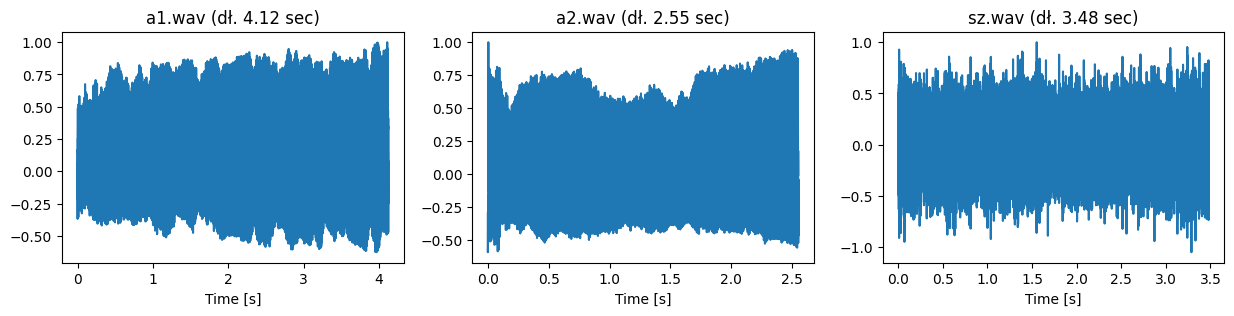

In [ ]:
# Wczytaj, wyświetl i  pliki audio
import IPython
display_Audio = lambda x,fs : IPython.display.display(IPython.display.Audio(x,rate=fs))

import librosa
import matplotlib.pyplot as plt
import numpy as np

signals = []
fig, ax = plt.subplots(1, 3, figsize=(15, 3))
# for f,i in zip(wavpaths, range(len(wavpaths))):
for i, f in enumerate(wavpaths):
    x, fs = librosa.load(f,sr=None)
    signals.append(x/np.max(x))
    ax[i].plot(np.arange(0,len(signals[i])/fs,1/fs),signals[i])
    ax[i].set_xlabel("Time [s]")
    ax[i].set_title("{} (dł. {} sec)".format(f,round(len(signals[i])/fs,2)))
    print(f)
    display_Audio(signals[i],fs)

### Ekstrakcja cech

Rozmiar podstawowej macierzy MFCC z a1.wav : (413, 11)
Rozmiar finalnej macierzy MFCC z a1.wav : (413, 22)
Rozmiar podstawowej macierzy MFCC z a2.wav : (256, 11)
Rozmiar finalnej macierzy MFCC z a2.wav : (256, 22)
Rozmiar podstawowej macierzy MFCC z sz.wav : (349, 11)
Rozmiar finalnej macierzy MFCC z sz.wav : (349, 22)


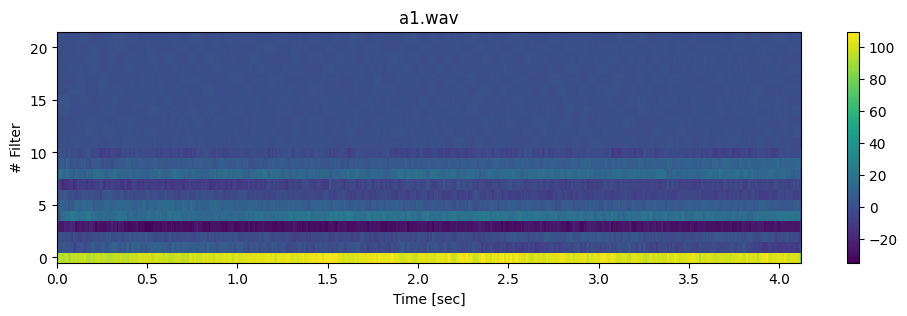

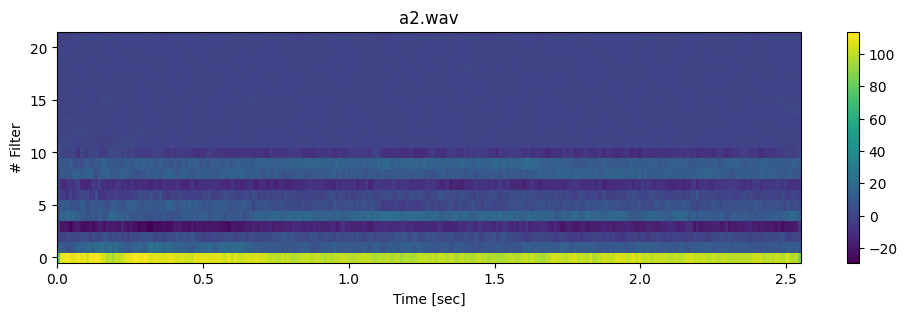

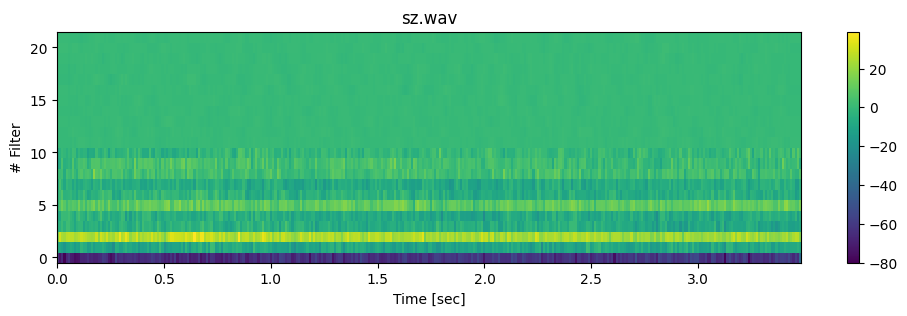

In [ ]:
# Oblicz MFCC dla każdego sygnału
import numpy as np
import librosa
def plot_2d(x,y,Z,title, ylab):
    fig = plt.figure(figsize=(12, 3))
    xmin,xmax = x.min(), x.max()
    ymin,ymax = y.min(), y.max()
    dy, = -np.diff([ymin,ymax])/(y.shape[0]-1)
    im1 = plt.imshow(Z, extent=[xmin, xmax, ymin+dy/2, ymax-dy/2],
                     aspect='auto', origin='lower', interpolation='none')
    plt.xlabel("Time [sec]")
    plt.title(title)
    plt.ylabel(ylab)
    fig.colorbar(im1)

mfccs = []
for x,fname in zip(signals, wavpaths):
    mfcc = librosa.feature.mfcc(y=x, sr=fs, n_mfcc=12, n_fft=512, win_length=320, hop_length=160, n_mels=40).T
    first_feature_id = 1
    mfcc = mfcc[:,first_feature_id:]  # porzucamy C0
    print(f"Rozmiar podstawowej macierzy MFCC z {fname} : {mfcc.shape}")
    deltas = librosa.feature.delta(mfcc.T).T   # Delty!!!!
    mfcc = np.concatenate((mfcc,deltas), axis=1)
    print(f"Rozmiar finalnej macierzy MFCC z {fname} : {mfcc.shape}")
    mfccs.append(mfcc)

    plot_2d(np.arange(0,np.shape(mfcc)[0])*0.01, np.arange(0,np.shape(mfcc)[1]),
            mfcc.T, fname, "# Filter")

### Modelowanie

In [ ]:
# Utwórz wielowymiarowy model Gaussa o jednym komponencie
# (każda cecha MFCC jest modelowana pojedynczą średnią i odchyleniem standardowym )

from sklearn import mixture
gmm1 = mixture.GaussianMixture(n_components=1, covariance_type='diag',
                              tol=0.0000001, reg_covar=1e-02, max_iter=100,
                              n_init=1, init_params='random', # random
                              weights_init=None, means_init=None,precisions_init=None,
                              random_state=1, warm_start=False,
                              verbose=3, verbose_interval=1)
gmm1.fit(mfccs[0]) # używamy cech z pierwszego a1
print(gmm1.score(mfccs[1]))

Initialization 0
  Iteration 1	 time lapse 0.00151s	 ll change inf
  Iteration 2	 time lapse 0.00072s	 ll change 0.00000
Initialization converged. time lapse 0.00225s	 lower bound -32.90902.
-56.82775117859758


In [ ]:
# Porównanie średnich
print("Średnie obliczone bezpośrednio z danych dla a1.wav:\n", np.mean(mfccs[0],axis=0))
print("Średnie obliczone bezpośrednio z danych dla a2.wav:\n", np.mean(mfccs[1],axis=0))
print("Średnie obliczone bezpośrednio z danych dla sz.wav:\n", np.mean(mfccs[2],axis=0))
print("Średnie z modelu Gaussa trenowanego na a1.wav:\n",gmm1.means_)
np.linalg.norm(gmm1.means_ - np.mean(mfccs[0],axis=0))

Średnie obliczone bezpośrednio z danych dla a1.wav:
 [ 1.01299965e+02 -3.42515111e-01 -6.65871024e-01 -2.75042133e+01
  1.78660564e+01  7.66407776e+00 -4.21700335e+00 -6.06835032e+00
  1.37763033e+01  6.72325611e+00 -3.39427209e+00  2.08767736e-03
 -2.05475427e-02 -2.29718350e-02  9.79015976e-03  2.42724698e-02
 -5.23565337e-03 -2.99021136e-02  2.44832356e-02 -2.44506374e-02
  1.56719200e-02 -4.46510082e-03]
Średnie obliczone bezpośrednio z danych dla a2.wav:
 [ 1.0146543e+02  1.2504444e+01  2.2875850e+00 -1.5872202e+01
  1.4813549e+01  5.8857613e+00  7.1693718e-01 -9.2900448e+00
  1.1956071e+01  1.3400368e+01 -6.0458102e+00 -2.7065318e-02
  1.0252889e-02 -1.4838241e-03  6.4733266e-03  6.5806517e-03
 -2.8144659e-02  1.9881066e-02 -9.3752583e-03  1.5470108e-02
  7.2728209e-03 -1.2050264e-02]
Średnie obliczone bezpośrednio z danych dla sz.wav:
 [-6.3322842e+01 -9.4830503e+00  2.3997557e+01 -6.1532660e+00
 -7.0103979e+00  9.6663551e+00 -4.5522552e+00 -7.0335221e+00
  2.6118076e+00  2.5707

np.float64(2.2797470206132737e-06)

In [ ]:
# Porównanie odchyleń standardowych
print("Odchylenia std. obliczone bezpośrednio z danych dla a1.wav:\n", np.std(mfccs[0],axis=0, ddof=0))
print("Odchylenia std. z modelu Gaussa dla a1.wav:\n",np.sqrt(gmm1.covariances_))
np.linalg.norm(np.sqrt(gmm1.covariances_) - np.std(mfccs[0],axis=0))

Odchylenia std. obliczone bezpośrednio z danych dla a1.wav:
 [3.6738017  5.0481834  2.8905437  2.6081042  2.953306   3.471733
 2.912656   3.261339   2.6428652  2.9961903  2.3562398  0.40211952
 0.40036482 0.35418725 0.37621957 0.46998224 0.35794115 0.371567
 0.35108247 0.43199217 0.2853972  0.36321086]
Odchylenia std. z modelu Gaussa dla a1.wav:
 [[3.67516057 5.04917389 2.8922728  2.61002054 2.95499869 3.47317283
  2.91437209 3.26287166 2.64475642 2.99785853 2.35836086 0.41436713
  0.41266451 0.36803343 0.3892829  0.48050316 0.37164751 0.38478833
  0.36504644 0.44341541 0.30240959 0.37672553]]


np.float64(0.04432992369630816)

### Określenie podobieństw (klasyfikacja)

In [ ]:
score0 = gmm1.score(mfccs[0])   # log( p(x_a1 | gmm_a1) ) test "wsobny"
score1 = gmm1.score(mfccs[1])   # log( p(x_a2 | gmm_a1) )
score2 = gmm1.score(mfccs[2])   # log( p(x_sz | gmm_a1) )

print(f"log p(x_a1 | gmm_a1) = {score0}")
print(f"log p(x_a2 | gmm_a1) = {score1}")
print(f"log p(x_sz | gmm_a1) = {score2}")

log p(x_a1 | gmm_a1) = -32.909020963108716
log p(x_a2 | gmm_a1) = -56.82775117859758
log p(x_sz | gmm_a1) = -1166.059922628887


## Naiwny klasyfikator Bayesa

Zadaniem klasyfikacji jest przyporządkowanie danych do jednej z $K$  klas $C = \{C_1, C_2, ..., C_K\}$. Podstawowym twierdzeniem wykorzystywanym w klasyfikatorach jest **Twierdzenie Bayesa**, które umożliwia obliczenie
prawdopodobieństwa *a posteriori* klasy. Twierdzenie możemy zapisać jako

\begin{equation}
 \textrm{P}(C_i|\textbf{X})=\frac{\textrm{p}(\textbf{X}|C_i)\textrm{P}(C_i)}{\textrm{p}(\textbf{X})},
\tag{1}
\end{equation}

gdzie $C_i$ oznacza $i$-tą klasę, natomiast $\textbf{X}$ próbę zmiennej losowej, czyli najczęściej zbiór obserwacji $\textbf{X} = [\textbf{x}_0, \textbf{x}_1, \textbf{x}_2, ..., \textbf{x}_{N-1}]$. W przypadku parametryzacji znanej z poprzednich zajęć, $\textbf{X}$ to po prostu macierz MFCC, natomiast $\textbf{x}_n = [x_{n0}, x_{n1}, ..., x_{n(D-1)}]^\textrm{T}$ to pojedynczy $D$ wymiarowy wektor cech MFCC obliczony dla $n$-tej ramki sygnału. W zadaniu klasyfikacyjnym chcemy określić która klasa jest najbardziej prawdopodobna mając dane $\textbf{X}$, czyli innymi słowy chcemy **porównać** wartości prawdopodobieństwa a posteriori $\textrm{P}(C_i|\textbf{X})$ dla różnych klas.


Korzystając z reguły Bayesa powinniśmy, więc wyznaczyć $\textrm{p}(\textbf{X}|C)$ (likelihood), $\textrm{P}(C)$ (prawdopodobieństwo a priori, "prior") oraz $\textrm{p}(\textbf{X})$ (prawdopodobieństwo danych). W praktyce nie wszystkie wartości są konieczne do samego określenia, która klasa jest najbardziej prawdopodobna przy obserwowanych danych.

$\textrm{p}(\textbf{X})$ to prawdopodobieństwo obserwacji (danych) i można je opisać wzorem


\begin{equation}
    \textrm{p}(\textbf{X}) = \sum_{i=0}^{K-1}{\textrm{p}(\textbf{X}|C_i)\textrm{P}(C_i)}.
    \tag{2}
\end{equation}

W praktyce można więc zauważyć, że licznik z równania (1) stanowi pojedynczy składnik sumy z równania (2). Dodatkowo warto zauważyć, że ta wartość specjalnie nie ma znaczenia w klasyfikacji, gdyż dla każdej klasy prawdopodobieństwo $\textrm{p}(\textbf{X})$ jest identyczne. Należy jednak pamiętać, że w celu wyznaczenia $ \textrm{p}(C_i|\textbf{X})$ normalizacja jest konieczna, gdyż w przeciwnym wypadku otrzymana wartość nie będzie prawdopodobieństwem.

$\textrm{P}(C_i)$ to prawdopodobieństwo *a priori* wystąpienia klasy i nazywane jest potocznie *priorem*. Jeśli klasy są równie prawdopodobne lub ich prawdopodobieństwo nie jest znane często przyjmuje się $\textrm{P}(C_i) = \frac{1}{K}$.

Przyjmując powyższe założenia dotyczące $\textrm{p}(\textbf{X})$ i $\textrm{P}(C_i)$ łatwo zauważyć, że prawdopodobieństwo *a posteriori* $ \textrm{P}(C_i|\textbf{X})$ zależy głównie od $\textrm{p}(\textbf{X}|C_i)$. Tej wartości na ogół nie możemy określić precyzyjnie, lecz możemy ją **estymować** używając przyjętego modelu danych klasy $C_i$, czyli

\begin{equation}
    \textrm{p}(\textbf{X}|C_i) \approx  \hat{\textrm{p}}(\textbf{X}|C_i) .
    \tag{3}
\end{equation}


W zależności od użytego modelu, $\hat{\textrm{p}}(\textbf{X}|C_i)$ może przyjmować różne wartości, które najczęściej nie są prawdopodobieństwami lecz wskazują miarę podobieństwa, czyli jak bardzo model jest podobny do danych (*likelihood*).


Przykładowo model oparty o jednokomponentowy rozkład Gaussa o diagonalnej macierzy kowariancji posiada 2 zestawy parametrów: wektor średnich $\boldsymbol{\mu}=[\mu_0, \mu_1, ..., \mu_{D-1}]^\textrm{T}$ i wektor odchyleń standardowych $\boldsymbol{\sigma} = [\sigma_0, \sigma_1, ..., \sigma_{D-1}]^\textrm{T}$. Używając [naiwnego klasyfikatora Bayesa](https://pl.wikipedia.org/wiki/Naiwny_klasyfikator_bayesowski) (brak korelacji między obserwacjami $\textbf{x}_n)$ otrzymujemy

\begin{equation}
    \hat{\textrm{p}}(\textbf{X}|C_i) = \textrm{p}(\textbf{X}|\boldsymbol{\mu},\boldsymbol{\sigma}) =\prod_{n=0}^{N-1}\textrm{p}(\textbf{x}_n|\boldsymbol{\mu},\boldsymbol{\sigma}),
    \tag{4}
\end{equation}

gdzie zakładając niezależność cech (diagonalna macierz kowariancji) wartość likelihood pojedynczej obserwacji $\textbf{x}_n$ wynosi

\begin{equation}
 \textrm{p}(\textbf{x}_n|\boldsymbol{\mu},\boldsymbol{\sigma}) = \prod_{d=0}^{D-1} \frac{1}{\sigma_d\sqrt{2\pi}}\textrm{exp}\bigg(\frac{-(x_{nd}-\mu_d)^2}{2\sigma_d^2}\bigg).
    \tag{5}
\end{equation}

Wzór (5) to iloczyn wartości funkcji gęstości prawdopodobieństwa dla $D$ wymiarów. Dodatkowo naiwny klasyfikator Bayesa zakłada, że następujące po sobie obserwacje są niezależne, co daje iloczyn we wzorze (4).

W praktyce nie oblicza się bezpośredniej wartości $\hat{\textrm{p}}(\textbf{X}|C_i)$, gdyż osiąga ona bardzo małe wartości wraz ze wzrostem liczby ramek w sygnale bądź liczby wymiarów cech i najczęściej jej zapis w komputerze byłby niemożliwy ze względu na ograniczoną dokładność maszyny. Dlatego zamiast bezpośrednich wartości funkcji gęstości prawdopodobieństwa (podobieństwa) używa się najczęściej skali logarytmicznej, czyli log-podobieństwa (log-likelihood). Umożliwia to zamianę iloczynów we wzorach (4) i (5) na sumy
\begin{equation}
    \textrm{log}\;\textrm{p}(\textbf{X}|C_i) =\textrm{log}\prod_{n=0}^{N-1}\textrm{p}(\textbf{x}_n|C_i) = \sum_{n=0}^{N-1} \textrm{log}\;\textrm{p}(\textbf{x}_n|C_i).
    \tag{6}
\end{equation}

W przypadku pakietu `sklearn.GaussianMixture` dodatkowo zamiast pełnej sumy  stosuje się wartość średnią log-podobieństwa i pojedyncza wartość zwracana przez funkcję `sklearn.GaussianMixture.score()` to *log-likelihood* wyrażony wzorem
\begin{equation}
   \textrm{score} = \frac{1}{N}\sum_{n=0}^{N-1} \textrm{log}\;\textrm{p}(\textbf{x}_n|C_i).
    \tag{7}
\end{equation}

## Histogram z rozkładem Gaussa*


Dla ułatwienia wykonania zadań w tym notatniku, poniższy przykład zawiera histogram losowych danych z nałożonym rozkładem Gaussa o zadanej średniej i odchyleniu standardowym. Zwróć uwagę, że w przypadku modelu GMM o więcej niż 1 komponencie należy uwzględnić również wagę komponentu.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Pseudolosowe 2-wymiarowe dane o zadanych średnich i odchyleniu standardowym
means = np.array([15, 40])
stdevs = np.array([3, 1])
Ndim = np.shape(means)[0]
Npoints = 1000
D = np.zeros((Npoints,Ndim))
for i in range(Ndim):
    D[:,i] = np.random.normal(loc=means[i], scale=stdevs[i], size=Npoints)

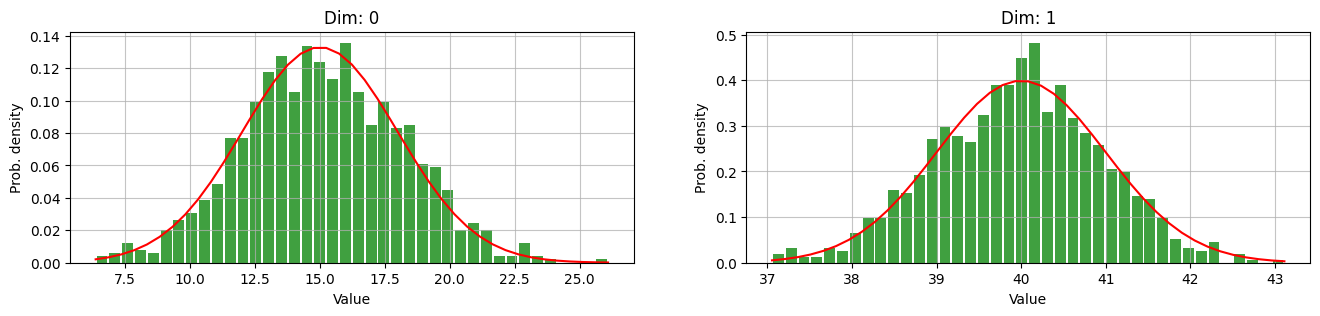

In [ ]:
# Histogramy wymiarów przeskalowane tak by pole pod wykresem było równe 1 (density=True)
dims = range(Ndim)
fig, ax = plt.subplots(1, Ndim, figsize=(16, 3))
for dim in dims:
    # histogram
    n, bins, patches = ax[dim].hist(x=D[:,dim], bins=40, color='green',
                                alpha=0.75, rwidth=0.85, density=True)
    ax[dim].grid(axis='both', alpha=0.75)
    ax[dim].set_xlabel('Value')
    ax[dim].set_ylabel('Prob. density')
    ax[dim].set_title("Dim: {}".format(dim))

    # rozkład Gaussa o średniej mu i odchyleniu stdev
    pdf = lambda x,mu,sigma : ((1 / (np.sqrt(2 * np.pi) * sigma)) *
                                np.exp(-0.5 * (1 / sigma * (bins - mu))**2))
    gauss_pdf = pdf(bins,means[dim], stdevs[dim])
    ax[dim].plot(bins, gauss_pdf ,color="red")

# Zadania

W poniższych zadaniach wykorzystaj modelowanie GMM oraz cechy MFCC aby stworzyć prosty klasyfikator rozróżniający 2 samogłoski - /i/ oraz /u/. Wykorzystaj nagrania o przedłużonej fonacji z poprzednich zajęć oraz nagraj nowe nagrania głosek /u/ oraz /i/ przez jednego z wcześniejszych mówców. Jeśli którekolwiek z posiadanych nagrań trwa krócej niż 3 sekundy, nagraj je ponownie.





Ustawienie środowiska (jeśli niepotrzebne to usuń pole):

In [ ]:
# W tym bloku zamontuj dysk Google, przejdź do katalogu grupy i wczytaj nagrane pliki
# Aby przejść katalog "w górę" w systemie UNIX używa się podwójnej kropki. Przykład (do usunięcia):
!ls ..

bin		   home		      opt		 sbin.usr-is-merged
bin.usr-is-merged  kaggle	      proc		 srv
boot		   lib		      python-apt	 sys
content		   lib64	      python-apt.tar.xz  tmp
datalab		   lib.usr-is-merged  root		 tools
dev		   media	      run		 usr
etc		   mnt		      sbin		 var



 W poniższym bloku kodu wykonaj parametryzację nagrań.


In [ ]:
# Wczytaj audio i oblicz macierze MFCC

##1. (2p) Analiza subiektywna modeli GMM


### 1.1 (0.2p) Trening modelu



Napisz funkcję, która przyjmuje jako argumenty wejściowe:
* macierz MFCC `mfcc`,
* wymaganą liczbę komponentów `n`,
* typ macierzy kowariancji `cov_type`,

oraz zwraca model GMM `gmm` o rozkładach dopasowanych do danych w `mfcc`. Funkcję wykorzystaj w następnych zadaniach.

In [ ]:
def train_gmm(mfcc, n, cov_type):
    # Zmodyfikuj/uzupełnij ciało funkcji zgodnie z opisem powyżej
    pass

### 1.2 (1p) Jakościowa analiza dopasowania modelu do danych (kod umożliwiajacy wyświetlenie histogramów i dopasowanych rozkładów)

Korzystając z **jednego** wybranego nagrania (macierzy MFCC) i odpowiedniej funkcji wyświetl histogramy cech oraz nałożone na nie wypadkowe rozkłady gęstości prawdopodobieństwa dla modeli GMM o liczbie komponentów równych **1,2,4,8**. Do analizy wybierz **dwie** cechy (wymiary MFCC) dla których najlepiej będzie widoczne modelowanie wieloma komponentami Gaussa (czyli te o rozkładzie najmniej przypominającym normalny). Poniższy kod powinien generować 2 wykresy po 4 subploty (2 cechy, 4 modele).

W tym celu najpierw napisz funkcję, która rysuje histogram przyjmującą macierz MFCC `mfcc`, listę obiektów modeli GMM `gmms`, numer cechy `m`, która umożliwia wizualną (subiektywną) analizę podobieństwa modeli do danych. Dla każdego modelu w liście `gmms` funkcja powinna generować subplot, na którym zawarte będą:

*  histogram cechy o indeksie `m`,
*  dopasowane funkcje gęstości prawdopodobieństwa z modelu GMM dla każdego komponentu osobno (np osobnymi kolorami)
*  wypadkowy rozkład otrzymany jako suma rozkładów wszystkich komponentów.

Dla 4 i mniej modeli subplot'y powinny być wyświetlane horyzontalnie.

Po otrzymaniu wykresów subiektywnie oceń jakość modelowania w zależności od liczby komponentów na podstawie otrzymanych wykresów. Jaka liczba komponentów jest Twoim zdaniem wystarczająca by poprawnie modelować analizowane cechy?
Odpowiedź wpisz w bloku tekstu poniżej.

In [ ]:
def plot_gmms_hist_fits(mfcc, gmms, m):
    # Uzupełnij ciało funkcji zgodnie z opisem powyżej
    pass

<font color="red">Odpowiedź na pytanie</font>

### 1.3 (0.4p) Obiektywnnie najlepsza liczba komponentów

Ile komponentów jest obiektywnie optymalnych w modelowaniu pojedynczej głoski?
Narysuj gradient wartości [Bayesian Information Criterion (BIC)](https://medium.com/data-science/gaussian-mixture-model-clusterization-how-to-select-the-number-of-components-clusters-553bef45f6e4) w zależności od liczby komponentów i wskaż liczbę dla której następuje ustabilizowanie BIC. Opis tej obiektywnej metody oceny modelu poza innymi znajduje się [tutaj](https://medium.com/data-science/gaussian-mixture-model-clusterization-how-to-select-the-number-of-components-clusters-553bef45f6e4).

In [ ]:
#Miejsce na kod

### 1.4 (0.4p) Szybkość treningu modelu w zależności od ilości danych



Dla modeli o 8 oraz 16 komponentach wyświetl wykresy przedstawiające zależność log-podobieństwa (GaussianMixture.score()) w zależności od liczby ramek użytych do treningu modelu pojedynczej głoski (dla jednego mówcy). Kolejne punkty powinny wskazywać na osi X liczbę ramek użytych do treningu modelu, więc w praktyce wykonaj wielokrotnie trening korzystając z coraz większej ilości danych treningowych. W ramach zadania powinny powstać 2 wykresy (dla modeli o 8 i 16 komponentach). Następnie na podstawie wykresów oszacuj minimalną liczbę ramek umożliwiajacą utworzenie modelu. Jeśli szacowanie jest niemożliwe uzasadnij to w odpowiedzi.

**Uwaga**: Warto wymusić podczas inicjalizacji modelu:
- (1) losowe parametry (zamiast estymowanych za pomocą K-means) oraz
- (2) ustalić stały parametr korzenia losowego (seed) w celu powtarzalności generowanego wykresu.

In [ ]:
# Miejsce na kod

<font color="red">Wniosek</font>

## 2. (1p) Klasyfikator Bayesa

### 2.1 (0.5p) Wyznaczanie średnich wartości log-podobieństwa

Na podstawie modeli GMM uzyskanych w zadaniu 1 dla jednego mówcy wyznacz średnie log-podobieństwa (loglikelihood):
* log(p(MFCC_U | GMM_U)) (jak nagranie U pasuje do modelu U),
* log(p(MFCC_I | GMM_U)) (jak nagranie I pasuje do modelu U),
* log(p(MFCC_I | GMM_I)) (jak nagranie I pasuje do modelu I),
* log(p(MFCC_U | GMM_I)) (jak nagranie U pasuje do modelu I).

Następnie odpowiedz na pytania:
1. Omów uzyskane wartości - czy są one zgodne z oczekiwaniami?
2. Wybierając klasę na podstawie najwyższego log-podobieństwa posługujesz się *naiwnym* klasyfikatorem Bayesa. Opisz **własnymi słowami** dlaczego konkretnie ten klasyfikator w tym kontekście jest nazywany *naiwnym*.


In [ ]:
# Miejsce na kod

<font color="red"> Odpowiedź </font>

### 2.2 (0.5p) Reguła Bayesa



Korzystając z reguły Bayesa oblicz 4 prawdopodobieństwa (P(GMM_x/MFCC_y)) dla nowo utworzonych nagrań głosek /u/ oraz /i/ dla tego samego mówcy  oraz dla innego mówcy. Przyjmij równe prawdopodobieństwa a priori klas. Na podstawie obliczonych wartości odpowiedz na pytania:
1. Czy nowe nagranie /u/ tego samego mówcy uzyskuje wyższe prawdopodobieństwo klasyfikacji jako /u/ czy jako /i/? Omów uzyskane wyniki.
2. Czy nagranie /u/ innego mówcy uzyskuje wyższe prawdopodobieństwo klasyfikacji jako /u/ czy jako /i/?

Bloki kodu i tekstu zorganizuj tak by rozwiązanie całego zadania **było czytelne.**


In [ ]:
# Oblicz prawdopodobieństwa

<font color="red"> Odpowiedź </font>

# Ocena
### <font color="orange"> * Przed ostatecznym zapisem usuń bloki zawierające gwiazdkę (*) w tytule. </font>

### * 1 termin tego zadania upływa **10.11.2026 o godz. 13:00**. Po skończonej pracy należy zapisać plik opcją `File > Save and pin revision`. Prowadzący oceniając odtworzy ostanią wersję w repozytorium notatnika sprzed daty oddania i ta wersja będzie podlegać ocenie.